In [1]:
import numpy as np
import matplotlib.pyplot as plt

(50,) (50,)
5.3523273311048944 20.723569384841127
[7.74  4.389 8.586]
[29.577 18.302 31.336]


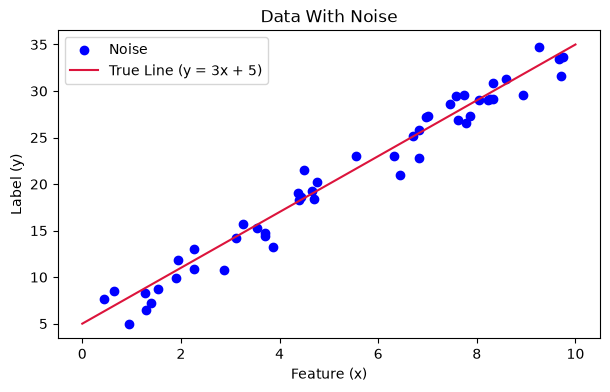

In [67]:
rng = np.random.default_rng(42)
x = rng.uniform(0, 10, 50)
y = 3 * x + 5 + rng.normal(0, 2, 50)


print(x.shape, y.shape)
print(x.mean(), y.mean())
print(x[:3].round(3))
print(y[:3].round(3))

x_line = np.linspace(0, 10, 100)
y_true = 3 * x_line + 5
plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="blue", label="Noise")
plt.plot(x_line, y_true, color="crimson", label="True Line (y = 3x + 5)")
plt.title("Data With Noise")
plt.xlabel("Feature (x)")
plt.ylabel("Label (y)")
plt.legend()
plt.show()

In [3]:
w_exact, b_exact = np.polyfit(x, y, 1)
print(round(w_exact, 3), round(b_exact, 3))

3.024 4.537


In [6]:
def predict(x, w, b):
    return w * x + b

def mse(y, y_hat):
    return np.mean((y_hat - y) ** 2)

def gradients(x, y, w, b):
    y_hat = predict(x, w, b)
    error = y_hat - y
    dw = (2 * error * x).mean()
    db = (2 * error).mean()
    return dw, db

In [ ]:
xt = np.array([1.0, 2.0, 3.0])
yt = np.array([2.0, 4.0, 6.0])  # the perfect line is w=2, b=0
print(mse(yt, predict(xt, 0, 0)))
print(gradients(xt, yt, 0, 0))
print(mse(yt, predict(xt, 2, 0)))
print(gradients(xt, yt, 2, 0))

#Both gradients are 0 because at w=2, b=0 the line fits every point exactly, so every error is 0.

18.666666666666668
(np.float64(-18.666666666666668), np.float64(-8.0))
0.0
(np.float64(0.0), np.float64(0.0))


In [28]:
def train(x, y, lr, epochs):
    w = 0.0
    b = 0.0
    history = []
    for epoch in range(epochs):
        dw, db = gradients(x, y, w, b)
        w = w - lr * dw
        b = b -lr * db
        loss = mse(y, predict(x, w, b))
        history.append(loss)
    return w, b, history

In [43]:
baseline = mse(y, predict(x, 0, 0))
print("Baseline:", round(baseline, 3))

w_final, b_final, history = train(x, y, 0.01, 1000)
print(f"Final Weights Found:")
print(f"  w = {round(w_final, 4)}")
print(f"  b = {round(b_final, 4)}")
print("-" * 30)
for step in [0, 9, 99, -1]:
    step_num = 1000 if step == -1 else step + 1
    print(f"Training: Step {step_num:4d} Loss -> {round(history[step], 3)}")


Baseline: 502.358
Final Weights Found:
  w = 3.0334
  b = 4.4751
------------------------------
Training: Step    1 Loss -> 38.424
Training: Step   10 Loss -> 5.422
Training: Step  100 Loss -> 3.773
Training: Step 1000 Loss -> 2.295


In [68]:
settings = [(0.01, 1000), (0.01, 5000), (0.001, 1000), (0.05, 1000)]
results = {}
for lr, epochs in settings:
    w_, b_, h_ = train(x, y, lr, epochs)
    results[(lr, epochs)] = (w_, b_, h_)
    print(f"lr={lr:<6} epochs={epochs:<5} w={w_:.4f} b={b_:.4f} final loss={h_[-1]:.4f}")

lr=0.01   epochs=1000  w=3.0334 b=4.4751 final loss=2.2947
lr=0.01   epochs=5000  w=3.0242 b=4.5373 final loss=2.2939
lr=0.001  epochs=1000  w=3.4151 b=1.8961 final loss=3.7748
lr=0.05   epochs=1000  w=nan b=nan final loss=nan


c:\Users\hknia\ai-ml-30days\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\hknia\AppData\Local\Temp\ipykernel_39100\3695907943.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_hat - y) ** 2)
C:\Users\hknia\AppData\Local\Temp\ipykernel_39100\2331248367.py:7: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - lr * dw


- The learning rate controls the size of each update step in w = w - lr * dw so it sets how far w and b move downhill on each update.
- If the learning rate is too small, for example lr = 0.001, after 1000 epochs w = 3.4151, b = 1.8961. It is still so far to match the polyfit answer, so it becomes incredibly slow to train and requires more epochs to train or else the training will not finish.
- If the learning rate is too big for example lr = 0.05 after 1000 epochs w = nan, b = nan, the model will overshoot, and the loss grows each step and numbers overflow into nan.
- lr = 0.01 with 5000 epochs matches np.polyfit.

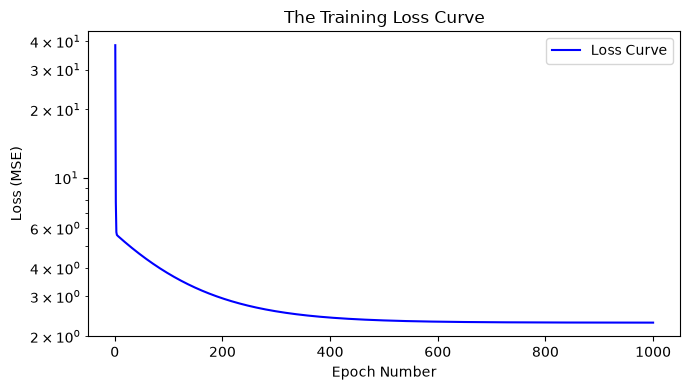

In [53]:
w, b, history = train(x, y, 0.01, 1000)
epochs = range(1, len(history) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history, color="blue", label="Loss Curve")
plt.yscale("log")
plt.xlabel("Epoch Number")
plt.ylabel("Loss (MSE)")
plt.title("The Training Loss Curve")
plt.legend()
plt.tight_layout()
plt.show()

- The loss went down fast at the start and slowly at the end. It fell from 502.36 (at w = 0, b = 0) to 38.42 after the first update and to 5.42 after 10 updates. After that it flattened out: 3.77 after 100 updates and 2.2947 after 1000 updates. The curve flattens at about 2.29, not at 0, because of the noise in the data. No straight line can pass through all 50 points, so about 2.29 is the lowest loss a line can reach here. When training is finished, the curve is almost flat.

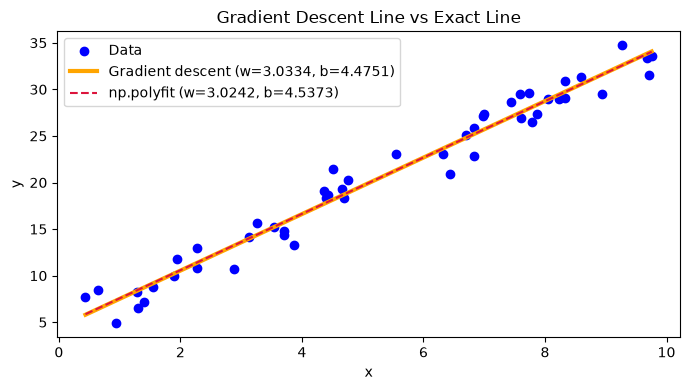

In [63]:
x_line = np.linspace(x.min(), x.max(), 100)     # 100 evenly spaced x values

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="blue", label="Data")
plt.plot(x_line, predict(x_line, w, b), color="orange", linewidth=3,
         label=f"Gradient descent (w={w:.4f}, b={b:.4f})")
plt.plot(x_line, predict(x_line, w_exact, b_exact), color="crimson", linestyle="--",
         label=f"np.polyfit (w={w_exact:.4f}, b={b_exact:.4f})")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Gradient Descent Line vs Exact Line")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

**Findings**
1. With lr = 0.01 and 1000 epochs, gradient descent reduced the loss from 502.36 (at w = 0, b = 0) to 2.2947 and reached w = 3.0334 and b = 4.4751, close to the exact answer from np.polyfit (w = 3.0242, b = 4.5373).
2. With lr = 0.01 and 5000 epochs, gradient descent reached w = 3.0242 and b = 4.5373, the same as np.polyfit to 4 decimals (loss 2.2939). In the plot, the gradient descent line and the polyfit line sit almost on top of each other.
3. The learning rate decides whether training works. With lr = 0.001 and 1000 epochs, training was not finished (w = 3.4151, b = 1.8961, loss 3.77). With lr = 0.05, every step overshot the minimum, the loss grew at each step, and the numbers overflowed into nan (w = nan, b = nan).

**Caveat**
- The result depends on the learning rate and the number of epochs, as the three runs above show. It also uses only 50 synthetic points, so the exact numbers will change with different data.

**Why gradient descent when np.polyfit already gives the exact answer?**
- A straight line has a direct formula, but models with millions of weights, such as neural networks, have no such formula (or solving it is far too expensive). Gradient descent only needs the gradient of the loss, so it works on any differentiable model and improves the weights step by step.